In [ ]:
import os
print(os.getcwd())
print(os.listdir())


/home/jovyan
['.profile', 'training', 'sector_validation_sample.csv', '.ipython', '.local', '.cache', 'lost+found', 'Terrorizer-main.zip', '.ipynb_checkpoints', '.condarc', '.config', '.code-server', 'PATSTAT_500_label_datav4.csv', '.jlab_bookmarks', '.conda', '.jupyter', '.npm', '.bashrc', 'outputs']


In [2]:
import re
import unicodedata
from datetime import date
from pathlib import Path
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sqlalchemy import func, or_
from IPython.display import display
from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN, TLS202_APPLN_TITLE, TLS203_APPLN_ABSTR,
    TLS206_PERSON, TLS207_PERS_APPLN, TLS224_APPLN_CPC
)

In [ ]:
ENV = 'PROD'

NAME_METHOD = 'terrorizer'
GOLD_STANDARD_FILE = Path('PATSTAT_500_label_datav4.csv')
TERRORIZER_ZIP = Path('Terrorizer-main.zip')
RUN_TERRORIZER_GOLD = True
RUN_TERRORIZER_SECTOR = True
RUN_SCOPE_REVIEW = True
STEP1_NOTEBOOK = Path('step_1.ipynb')

# The kernel runs on TIP (/home/jovyan), not next to this notebook on your PC.
# Files that are missing there are downloaded from their public sources
# (byte-identical to the copies in this folder; the Terrorizer ZIP has the SHA256 recorded in the Terrorizer notebook).
import urllib.request
INPUT_URLS = {
    GOLD_STANDARD_FILE: 'https://raw.githubusercontent.com/graziasveva/innovation-management-datascience26/main/tutorial_1/PATSTAT_500_label_datav4.csv',
    TERRORIZER_ZIP: 'https://github.com/graziasveva/Terrorizer/archive/refs/heads/main.zip',
}
for local_file, url in INPUT_URLS.items():
    if not local_file.exists():
        urllib.request.urlretrieve(url, local_file)
        print('Downloaded:', local_file.resolve())
    else:
        print('Found:', local_file.resolve())
if not STEP1_NOTEBOOK.exists():
    print(f'Not found: {STEP1_NOTEBOOK.resolve()} (upload step_1.ipynb there to enable the Step 1 comparison; optional)')
PEST_GROUP_AGREED = False
FINAL_SIGNOFF = False
TERRORIZER_SAMPLE_SIZE = 200
TERRORIZER_RANDOM_SEED = 42
TERRORIZER_MAX_BLOCK_SIZE = 250

OUTPUT_DIR = Path('outputs/step2') / ENV.lower() / 'quality_gated'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SECTOR_NAME = 'Surface Drones'
SECTOR_CPC_PREFIXES = (
    'B63B2035/006', 'B63B2035/007', 'B63B2035/008',
    'G05D1/00', 'G05D1/0206', 'G08G3/00', 'B63B35/00',
    'B63G8/001', 'B63G13/00', 'B64U60/10', 'B64U70/93'
)
keywords_primary = [
    'unmanned surface vehicle', 'USV', 'unmanned surface vessel',
    'autonomous surface vehicle', 'ASV', 'autonomous surface vessel',
    'unmanned surface drone', 'maritime drone', 'marine drone',
    'aquatic drone', 'waterborne drone', 'remotely operated surface vessel',
    'crewless vessel', 'uncrewed surface vessel', 'robotic boat',
    'robotic vessel', 'autonomous boat'
]
keywords_form_factor = [
    'surface craft', 'surface vessel', 'surface platform',
    'unmanned catamaran', 'unmanned trimaran', 'unmanned kayak',
    'semi-submersible surface vehicle', 'autonomous hydrofoil',
    'wave glider', 'saildrone'
]
keywords_subsystems = {
    'navigation_autonomy': [
        'obstacle avoidance', 'path planning', 'colregs compliance',
        'collision avoidance', 'waypoint navigation',
        'autonomous docking', 'dynamic positioning'
    ],
    'control_telemetry': [
        'teleoperation', 'line-of-sight communication',
        'satellite communication', 'SATCOM',
        'tethered control', 'ground control station', 'GCS'
    ],
    'propulsion_energy': [
        'hybrid propulsion', 'electric outboard',
        'wave propulsion', 'solar sails', 'rigid sail',
        'waterjet propulsion', 'thruster configuration'
    ],
    'payload_deployment': [
        'LARS', 'launch and recovery system', 'moon pool',
        'tether winch', 'bathymetric sonar',
        'multibeam echosounder', 'ROV deployment', 'UAV landing pad'
    ]
}
SECTOR_KEYWORDS = (keywords_primary + keywords_form_factor + [
    term for group in keywords_subsystems.values() for term in group
])

YEAR_MIN, YEAR_MAX = 2000, 2025
LAST_COMPLETE_YEAR = 2022
IPR_TYPE = 'PI'
SPLIT_YEAR = 2015
WINDOW = 3
TOP_N = 15
QUERY_BATCH = 150

assert NAME_METHOD == 'terrorizer' and RUN_TERRORIZER_SECTOR
assert 2 <= TERRORIZER_MAX_BLOCK_SIZE <= 250
assert len(SECTOR_CPC_PREFIXES) == 11 and len(SECTOR_KEYWORDS) == 56
assert YEAR_MIN <= SPLIT_YEAR <= LAST_COMPLETE_YEAR <= YEAR_MAX

Found: /home/jovyan/PATSTAT_500_label_datav4.csv
Found: /home/jovyan/Terrorizer-main.zip
Not found: /home/jovyan/step_1.ipynb (upload step_1.ipynb there to enable the Step 1 comparison; optional)


In [ ]:
import ast
import json

step1_definition_match = None
step1_check_message = 'Step 1 file not available here'

if STEP1_NOTEBOOK.exists():
    try:
        step1_nb = json.loads(STEP1_NOTEBOOK.read_text(encoding='utf-8'))
        step1_source = ''.join(step1_nb['cells'][4]['source'])
        parsed = {}
        for statement in ast.parse(step1_source).body:
            if isinstance(statement, ast.Assign):
                try:
                    value = ast.literal_eval(statement.value)
                except (TypeError, ValueError, SyntaxError):
                    continue
                for target in statement.targets:
                    if isinstance(target, ast.Name):
                        parsed[target.id] = value
                    elif isinstance(target, (ast.Tuple, ast.List)) and isinstance(value, (tuple, list)):
                        for elt, val in zip(target.elts, value):
                            if isinstance(elt, ast.Name):
                                parsed[elt.id] = val
        step1_keywords = (
            parsed['keywords_primary'] + parsed['keywords_form_factor']
            + [term for group in parsed['keywords_subsystems'].values() for term in group]
        )
        expected_cutoff = parsed['YEAR_MAX'] - max(
            parsed['TRUNCATED_YEARS'][parsed['FAMILY_TIME_COLUMN']],
            parsed['TRUNCATED_YEARS'][parsed['APPLN_TIME_COLUMN']]
        )
        checks = {
            'CPC prefixes': tuple(parsed['SECTOR_CPC_PREFIXES']) == tuple(SECTOR_CPC_PREFIXES),
            'Keywords': step1_keywords == SECTOR_KEYWORDS,
            'Year range': (parsed['YEAR_MIN'], parsed['YEAR_MAX']) == (YEAR_MIN, YEAR_MAX),
            'Complete-year cutoff': expected_cutoff == LAST_COMPLETE_YEAR,
        }
        step1_definition_match = all(checks.values())
        step1_check_message = 'MATCH' if step1_definition_match else 'DIFFERENCE FOUND'
        display(pd.DataFrame({'check': checks.keys(), 'matches_step1': checks.values()}))
    except (KeyError, IndexError, ValueError, SyntaxError, OSError) as exc:
        step1_check_message = f'Unable to read the Step 1 configuration: {exc}'
print('Step 1 scope comparison:', step1_check_message)

Step 1 scope comparison: Step 1 file not available here


In [ ]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

def keyword_condition(terms):

    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(*(col.like(f"%{term.lower()}%")
                 for term in terms for col in (title, abstract)))

def symbol_prefix_condition(symbol_column, codes):

    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))

def batches(values, n=QUERY_BATCH):
    for start in range(0, len(values), n):
        yield values[start:start + n]

In [ ]:
LEGAL_FORMS = {
    "INC", "INCORPORATED", "CORP", "CORPORATION", "CO", "COMPANY", "LTD", "LIMITED", "LLC", "LP", "PLC",
    "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS", "SPA", "SRL", "BV", "NV", "AB", "AS", "ASA", "OY", "OYJ",
    "KK", "KABUSHIKI", "KAISHA", "LTDA", "PTY", "THE", "AKTIENGESELLSCHAFT", "GESELLSCHAFT",
}

def clean_with_dictionary(name):

    text = unicodedata.normalize('NFKC', str(name)).upper()
    words = re.sub(r"[^\w\s]", " ", text).replace('_', ' ').split()
    while words and words[-1] in LEGAL_FORMS:
        words.pop()
    while words and words[0] in LEGAL_FORMS:
        words.pop(0)
    return " ".join(words)

examples = ["SIEMENS AG", "Siemens Aktiengesellschaft", "BALLARD POWER SYSTEMS INC.", "Ballard Power Systems",
            "TOYOTA JIDOSHA KABUSHIKI KAISHA", "KABUSHIKI KAISHA TOSHIBA", "Toyota Motor Corp",
            "FIAT S.p.A.", "Umicore N.V."]
pd.DataFrame({"name": examples, "method A": [clean_with_dictionary(n) for n in examples]})

,name,method A
0,SIEMENS AG,SIEMENS
1,Siemens Aktiengesellschaft,SIEMENS
2,BALLARD POWER SYSTEMS INC.,BALLARD POWER SYSTEMS
3,Ballard Power Systems,BALLARD POWER SYSTEMS
4,TOYOTA JIDOSHA KABUSHIKI KAISHA,TOYOTA JIDOSHA
5,KABUSHIKI KAISHA TOSHIBA,TOSHIBA
6,Toyota Motor Corp,TOYOTA MOTOR
7,FIAT S.p.A.,FIAT S P A
8,Umicore N.V.,UMICORE N V


In [7]:
%pip install cleanco


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
from cleanco import basename

def clean_with_cleanco(name):

    return clean_with_dictionary(basename(str(name)))

pd.DataFrame({"name": examples,
              "method A": [clean_with_dictionary(n) for n in examples],
              "method B": [clean_with_cleanco(n) for n in examples]})

,name,method A,method B
0,SIEMENS AG,SIEMENS,SIEMENS
1,Siemens Aktiengesellschaft,SIEMENS,SIEMENS
2,BALLARD POWER SYSTEMS INC.,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS
3,Ballard Power Systems,BALLARD POWER SYSTEMS,BALLARD POWER SYSTEMS
4,TOYOTA JIDOSHA KABUSHIKI KAISHA,TOYOTA JIDOSHA,TOYOTA JIDOSHA
5,KABUSHIKI KAISHA TOSHIBA,TOSHIBA,TOSHIBA
6,Toyota Motor Corp,TOYOTA MOTOR,TOYOTA MOTOR
7,FIAT S.p.A.,FIAT S P A,FIAT
8,Umicore N.V.,UMICORE N V,UMICORE


In [ ]:
def applicant_type(psn_sector):

    s = str(psn_sector).upper()
    if 'UNIVERSITY' in s:
        return 'university'
    if 'COMPANY' in s:
        return 'firm'
    if 'GOV' in s:
        return 'government / non-profit'
    if 'HOSPITAL' in s:
        return 'hospital'
    if 'INDIVIDUAL' in s:
        return 'individual'
    return 'unknown'

def consolidated_names(psn_names, method=None, terrorizer_map=None):

    method = NAME_METHOD if method is None else method
    names = sorted({str(x).strip() for x in psn_names if pd.notna(x) and str(x).strip()})
    if method == 'terrorizer':
        if not terrorizer_map:
            raise ValueError('Terrorizer assignments are missing; run the full sector cell first')
        missing = set(names) - set(terrorizer_map)
        if missing:
            raise ValueError(f'Terrorizer is missing {len(missing)} names (e.g. {sorted(missing)[:3]})')
        return {name: terrorizer_map[name] for name in names}
    if method not in ('dictionary', 'cleanco'):
        raise ValueError(f'Unknown name method: {method}')
    cleaner = clean_with_dictionary if method == 'dictionary' else clean_with_cleanco
    return {name: cleaner(name) or name for name in names}

def prepare_applicants(raw, method=None, terrorizer_map=None):

    df = raw.copy()
    df['psn_name'] = df['psn_name'].fillna('').astype(str).str.strip()
    df = df[df['psn_name'].ne('')].copy()
    name_map = consolidated_names(df['psn_name'], method=method, terrorizer_map=terrorizer_map)
    df['applicant'] = df['psn_name'].map(name_map)
    if df['applicant'].isna().any():
        raise ValueError('Some applicants were not harmonised')
    df['type'] = df['psn_sector'].map(applicant_type)
    df['ctry'] = df['ctry'].replace('', np.nan)
    known = df.dropna(subset=['ctry']).drop_duplicates(['unit_id', 'applicant', 'ctry'])
    main_country = known.groupby('applicant')['ctry'].agg(lambda c: c.value_counts().index[0])
    df['ctry'] = df['applicant'].map(main_country)
    types = df.groupby('applicant')['type'].agg(
        lambda s: s.iloc[0] if s.nunique() == 1 else 'mixed'
    )
    df['type'] = df['applicant'].map(types)
    return df[['unit_id', 'year', 'applicant', 'type', 'ctry']].drop_duplicates(['unit_id', 'applicant'])

In [10]:
if GOLD_STANDARD_FILE.exists():
    gold = pd.read_csv(GOLD_STANDARD_FILE).rename(
        columns={'comp': 'name', 'Group': 'gold_group'}
    )[['name', 'gold_group']].dropna().drop_duplicates('name').reset_index(drop=True)
    print(f"{len(gold):,} names in {gold['gold_group'].nunique():,} organisations")
    display(gold.head(10))
else:
    gold = pd.DataFrame(columns=['name', 'gold_group'])
    print(f'Gold Standard unavailable: {GOLD_STANDARD_FILE}')

3,192 names in 481 organisations


,name,gold_group
0,NOKIA CORPORATION,1
1,NOKIA (DEUTSCHLAND),1
2,NOKIA GRAETZ,1
3,NOKIA SIEMENS NETWORKS SCHWEIZ,2
4,NOKIA,1
5,NOKIA MOBILE PHONES (U.K.) LIMITED,1
6,NOKIA SIEMENS NETWORKS S.P.A.,2
7,NOKIA SIEMENS NETWORKS,2
8,NOKIA COMMUNICATION,1
9,NOKIA HIGH SPEED ACCESS PRODUCTS,1


In [11]:
from math import comb

def pairs_inside(group_sizes):

    return sum(comb(int(n), 2) for n in group_sizes)

def precision_recall_f1(gold_groups, predicted_groups):

    df = pd.DataFrame({"gold": list(gold_groups), "pred": list(predicted_groups)})
    tp = pairs_inside(df.groupby(["gold", "pred"]).size())
    tp_fp = pairs_inside(df.groupby("pred").size())
    tp_fn = pairs_inside(df.groupby("gold").size())
    precision = tp / tp_fp if tp_fp else 1.0
    recall = tp / tp_fn
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"groups found": df["pred"].nunique(), "precision": precision, "recall": recall, "F1": f1}

if not gold.empty:
    method_scores = pd.DataFrame([
        {'method': method, **precision_recall_f1(
            gold['gold_group'], gold['name'].map(cleaner))}
        for method, cleaner in [
            ('Dictionary', clean_with_dictionary),
            ('Cleanco', clean_with_cleanco)
        ]
    ])
    display(method_scores.round(4))
    method_scores.to_csv(OUTPUT_DIR / 'gold_standard_methods.csv', index=False)

,method,groups found,precision,recall,F1
0,Dictionary,3010,0.9952,0.0022,0.0045
1,Cleanco,2984,0.9960,0.0027,0.0054


In [12]:
import os
import sys
import zipfile
from contextlib import contextmanager
from functools import lru_cache
from collections import defaultdict
import hashlib
import random

TERRORIZER_MODEL_ID = 'Vsevolod/company-names-similarity-sentence-transformer'
TERRORIZER_SAME_TOKEN = 0.30
TERRORIZER_FIRST_TOKEN = 0.20
TERRORIZER_SIMILARITY = 1.00
TERRORIZER_MATCH_THRESHOLD = 0.87
TERRORIZER_BRIDGENESS_THRESHOLD = 0.10
TERRORIZER_RESOLUTION = 1.0

@contextmanager
def working_directory(path):
    old = Path.cwd()
    path.mkdir(parents=True, exist_ok=True)
    try:
        os.chdir(path)
        yield
    finally:
        os.chdir(old)

def flatten_groups(result):
    groups = []
    for entry in result.values():
        if isinstance(entry, set):
            groups.append(entry)
        elif isinstance(entry, (list, tuple)):
            groups.extend(entry)
        else:
            raise TypeError(f'Unexpected community representation: {type(entry)}')
    return groups

@lru_cache(maxsize=1)
def load_terrorizer_model():
    from sentence_transformers import SentenceTransformer
    return SentenceTransformer(TERRORIZER_MODEL_ID, device='cpu')

def run_terrorizer_pilot(names, result_folder):

    names = pd.Series(names, dtype=str).reset_index(drop=True)
    if not 2 <= len(names) <= 250 or names.duplicated().any():
        raise ValueError('Terrorizer pilot requires 2–250 distinct names')
    if not TERRORIZER_ZIP.exists():
        raise FileNotFoundError(f'Original Terrorizer source not found: {TERRORIZER_ZIP}')
    source_folder = OUTPUT_DIR / '_terrorizer_source'
    required = ('bridges.py', 'preprocessing_class_terrorizer.py',
                'process_network_terrorizer.py', 'vectorizer_class2.py')
    with zipfile.ZipFile(TERRORIZER_ZIP) as z:
        for filename in required:
            matches = [entry for entry in z.namelist() if entry.endswith('/' + filename)]
            if len(matches) != 1:
                raise ValueError(f'Expected one {filename} in the source ZIP')
            source_folder.mkdir(exist_ok=True)
            (source_folder / filename).write_bytes(z.read(matches[0]))
    if str(source_folder.resolve()) not in sys.path:
        sys.path.insert(0, str(source_folder.resolve()))

    from preprocessing_class_terrorizer import NamesPreprocessing
    from process_network_terrorizer import terrorizer_matching_stage, process_network

    preprocessor = NamesPreprocessing.__new__(NamesPreprocessing)
    frame = pd.DataFrame({'original_name': names.tolist()})
    normal = preprocessor.preprocess(frame, default_column='original_name')
    normal['name'] = normal['original_name']
    normal['name_normalized'] = normal['name_normalized'].fillna('').astype(str)
    missing = normal['name_normalized'].str.strip().eq('')
    normal.loc[missing, 'name_normalized'] = normal.loc[missing, 'original_name'].str.lower()
    if len(normal) != len(names):
        raise ValueError('Preprocessing changed the number of names')

    model = load_terrorizer_model()
    vectors = model.encode(normal['name_normalized'].tolist(),
                           convert_to_numpy=True, batch_size=16,
                           normalize_embeddings=False, show_progress_bar=False)
    if vectors.shape[0] != len(names) or not np.isfinite(vectors).all():
        raise ValueError('Invalid embedding matrix')

    random.seed(TERRORIZER_RANDOM_SEED)
    np.random.seed(TERRORIZER_RANDOM_SEED)
    with working_directory(result_folder):
        matcher = terrorizer_matching_stage(
            data=normal[['original_name', 'name_normalized', 'name']].copy(),
            vectors=vectors, weight_same_t=TERRORIZER_SAME_TOKEN,
            weight_first_token=TERRORIZER_FIRST_TOKEN,
            weight_similarity=TERRORIZER_SIMILARITY,
            weight_in_domain=0, weight_token_text=0)
        pair_scores = matcher.main()
        if len(pair_scores) != len(names):
            raise ValueError('Terrorizer returned unexpected pair-score rows')
        network = process_network(
            results_normal=pair_scores, resolution=TERRORIZER_RESOLUTION,
            match_threshold=TERRORIZER_MATCH_THRESHOLD,
            bridgeness_threshold=TERRORIZER_BRIDGENESS_THRESHOLD)
        communities = network.main()

    assignment = {}
    for cluster_id, group in enumerate(flatten_groups(communities)):
        for row_index in group:
            row_index = int(row_index)
            if row_index in assignment:
                raise ValueError('Overlapping communities')
            assignment[row_index] = cluster_id
    if set(assignment) != set(range(len(names))):
        raise ValueError('Some names have no predicted cluster')
    return pd.DataFrame({
        'name': names, 'terrorizer_group': [assignment[i] for i in range(len(names))]
    })

def terrorizer_block_key(name):

    cleaned = clean_with_dictionary(name)
    tokens = cleaned.split()
    return tokens[0] if tokens else 'RAW_' + str(name).strip().upper()

def run_terrorizer_all_names(names, frequencies, output_folder):

    names = sorted({str(x).strip() for x in names if pd.notna(x) and str(x).strip()})
    if not names:
        raise ValueError('No non-empty applicant names to harmonise')
    blocks = defaultdict(list)
    for name in names:
        blocks[terrorizer_block_key(name)].append(name)

    too_large = [(key, len(members)) for key, members in blocks.items()
                 if len(members) > TERRORIZER_MAX_BLOCK_SIZE]
    if too_large:
        raise ValueError('One or more Terrorizer blocks exceed the safety limit. '
                         'Review the blocking strategy rather than silently sampling: '
                         + str(too_large[:8]))

    all_groups = []
    model_calls = 0
    for key, members in sorted(blocks.items()):
        if len(members) == 1:
            all_groups.append((key, members))
            continue
        safe_id = hashlib.sha256(key.encode('utf-8')).hexdigest()[:16]
        local = run_terrorizer_pilot(pd.Series(members), output_folder / f'block_{safe_id}')
        if set(local['name']) != set(members) or local['name'].duplicated().any():
            raise ValueError(f'Mismatch in Terrorizer output for block: {key}')
        for _, group in local.groupby('terrorizer_group'):
            all_groups.append((key, sorted(group['name'].tolist())))
        model_calls += 1

    all_groups.sort(key=lambda group: (group[0], group[1][0]))
    rows, group_rows = [], []
    for group_id, (key, members) in enumerate(all_groups):
        representative = sorted(members, key=lambda n: (-int(frequencies.get(n, 0)), -len(n), n))[0]
        label = clean_with_dictionary(representative) or representative
        group_rows.append({
            'group_id': group_id,
            'block_key': key,
            'n_names': len(members),
            'representative': representative,
            'consolidated_applicant': label,
            'source_names': ' | '.join(members),
            'review_status': 'NOT_REVIEWED' if len(members) > 1 else 'SINGLETON'
        })
        for name in members:
            rows.append({'psn_name': name, 'group_id': group_id,
                         'block_key': key, 'consolidated_applicant': label,
                         'group_size': len(members)})

    assignments = pd.DataFrame(rows)
    groups = pd.DataFrame(group_rows)

    duplicate_labels = groups['consolidated_applicant'].duplicated(keep=False)
    if duplicate_labels.any():
        group_label = {
            int(row['group_id']): (
                f"{row['consolidated_applicant']} [TG{int(row['group_id']):05d}]"
                if duplicate_labels.loc[idx] else row['consolidated_applicant']
            )
            for idx, row in groups.iterrows()
        }
        groups['consolidated_applicant'] = groups['group_id'].map(group_label)
        assignments['consolidated_applicant'] = assignments['group_id'].map(group_label)
        print(f"Disambiguated {int(duplicate_labels.sum())} repeated display labels "
              "to prevent cross-cluster merges.")
    if groups['consolidated_applicant'].duplicated().any():
        raise ValueError('Terrorizer group labels must be unique')
    if len(assignments) != len(names) or assignments['psn_name'].duplicated().any():
        raise ValueError('Terrorizer must assign every distinct sector name once')
    if set(assignments['psn_name']) != set(names):
        raise ValueError('Name-coverage check failed')
    print(f'Terrorizer coverage: {len(names):,}/{len(names):,} names across '
          f'{len(blocks):,} blocks ({model_calls:,} blocks run through the model).')
    print(f'Groups: {len(groups):,}; groups with multiple names: '
          f'{int(groups["n_names"].gt(1).sum()):,}.')
    return assignments, groups

In [13]:
if RUN_TERRORIZER_GOLD or RUN_TERRORIZER_SECTOR:
    get_ipython().run_line_magic(
        'pip',
        'install -q nltk numba scikit-learn gensim toolz tldextract swifter optuna joblib atpbar mantichora pandarallel sentence-transformers networkx'
    )
else:
    print('Optional Terrorizer dependencies skipped.')


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [14]:
if RUN_TERRORIZER_GOLD:
    if gold.empty:
        raise ValueError('Gold Standard is required for Terrorizer evaluation')
    rng = np.random.default_rng(TERRORIZER_RANDOM_SEED)
    group_list = [g for _, g in gold.groupby('gold_group') if len(g) >= 2]
    rng.shuffle(group_list)
    picked = pd.concat([g.sample(min(3, len(g)), random_state=TERRORIZER_RANDOM_SEED)
                        for g in group_list[:40]], ignore_index=True)
    remaining = gold[~gold['name'].isin(picked['name'])]
    if len(picked) < TERRORIZER_SAMPLE_SIZE:
        picked = pd.concat([picked, remaining.sample(
            min(TERRORIZER_SAMPLE_SIZE - len(picked), len(remaining)),
            random_state=TERRORIZER_RANDOM_SEED
        )], ignore_index=True)
    gold_sample = picked.head(TERRORIZER_SAMPLE_SIZE).copy().reset_index(drop=True)
    eval_assignments, eval_groups = run_terrorizer_all_names(
        gold_sample['name'], gold_sample['name'].value_counts().to_dict(),
        OUTPUT_DIR / 'terrorizer_gold_blocked'
    )
    predicted = gold_sample['name'].map(eval_assignments.set_index('psn_name')['group_id'])
    if predicted.isna().any():
        raise ValueError('Missing a Gold Standard name in Terrorizer evaluation')
    pilot_scores = pd.DataFrame([
        {'method': label, **precision_recall_f1(gold_sample['gold_group'], values)}
        for label, values in [
            ('Dictionary', gold_sample['name'].map(clean_with_dictionary)),
            ('Cleanco', gold_sample['name'].map(clean_with_cleanco)),
            ('Terrorizer (blocked source-based)', predicted)
        ]
    ])
    display(pilot_scores.round(4))
    pilot_scores.to_csv(OUTPUT_DIR / 'terrorizer_gold_comparison.csv', index=False)
else:
    print('Gold Standard evaluation skipped; sector will still use Terrorizer.')

INFO: Pandarallel will run on 2 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Communities detection started
[{0, 1, 2, 3}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1, 2, 3}]
Communities detection started
[{0, 1, 2, 3}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1}]
Communities detection started
[{0, 1}]
Communities detection started
[{0, 1}]
Communities detection started
[{0, 1}]
Communities detection started
[{0}, {1}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1, 2}]
Communities detection started
[{0, 1}]
Communities detection started
[{1}, {0, 2}]
Communities detection started
[{0, 1, 2, 3, 4, 5, 6, 7}]
Communities detection started
[{0, 1}]
Communities detection started


,method,groups found,precision,recall,F1
0,Dictionary,198,1.0000,0.0078,0.0154
1,Cleanco,197,1.0000,0.0117,0.0231
2,Terrorizer (blocked source-based),98,0.8826,0.8482,0.8651


In [ ]:
def concentration_ratio(patents_per_firm, k):

    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100

def herfindahl(patents_per_firm):

    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)

def coefficient_of_variation(patents_per_firm):

    x = np.asarray(patents_per_firm, dtype=float)
    return x.std(ddof=1) / x.mean()

def lorenz_curve(patents_per_firm):

    x = np.sort(patents_per_firm)
    share_of_firms = np.arange(0, len(x) + 1) / len(x)
    share_of_patents = np.concatenate([[0], np.cumsum(x) / x.sum()])
    return share_of_firms, share_of_patents

def gini(patents_per_firm):

    share_of_firms, share_of_patents = lorenz_curve(patents_per_firm)

    widths = np.diff(share_of_firms)
    heights = (share_of_patents[1:] + share_of_patents[:-1]) / 2
    area_below_curve = np.sum(widths * heights)
    return (0.5 - area_below_curve) / 0.5

def lotka(patents_per_firm):

    f = pd.Series(patents_per_firm).value_counts().sort_index()
    if len(f) < 3:
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index), np.log(f.values))
    return fit.slope, fit.pvalue

def six_measures(patents_per_firm):

    lotka_slope, lotka_pvalue = lotka(patents_per_firm)
    return {
        "firms": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CV": coefficient_of_variation(patents_per_firm),
        "CR4 (%)": concentration_ratio(patents_per_firm, 4),
        "CR8 (%)": concentration_ratio(patents_per_firm, 8),
        "HH": herfindahl(patents_per_firm),
        "1/HH": 1 / herfindahl(patents_per_firm),
        "Lotka L": lotka_slope,
        "Lotka p-value": lotka_pvalue,
        "Gini": gini(patents_per_firm),
    }

In [16]:
by_cpc = (
    db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES))
)
sector_ids = by_cpc
if SECTOR_KEYWORDS:
    by_kw = (
        db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
        .outerjoin(TLS202_APPLN_TITLE,
                   TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR,
                   TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(SECTOR_KEYWORDS))
    )
    sector_ids = by_cpc.union(by_kw)

family_year = func.min(TLS201_APPLN.earliest_filing_year)
families = (
    db.query(TLS201_APPLN.docdb_family_id.label("unit_id"),
             family_year.label("year"))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(family_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)

q_sector = (
    db.query(families.c.unit_id, families.c.year,
             TLS206_PERSON.person_id, TLS206_PERSON.person_name,
             TLS206_PERSON.psn_id, TLS206_PERSON.psn_name,
             TLS206_PERSON.psn_sector,
             func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
    .select_from(families)
    .join(TLS201_APPLN,
          TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS207_PERS_APPLN,
          TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON,
          TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0,
            TLS201_APPLN.ipr_type == IPR_TYPE)
    .distinct()
)
raw_sector = patstat.df(q_sector)

q_cpc = (
    db.query(families.c.unit_id, families.c.year,
             func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("cpc"))
    .select_from(families)
    .join(TLS201_APPLN,
          TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS224_APPLN_CPC,
          TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    .distinct()
)
family_cpc = patstat.df(q_cpc)

required = {'unit_id', 'year', 'psn_id', 'psn_name', 'psn_sector', 'ctry'}
if not required.issubset(raw_sector.columns):
    raise ValueError(f"Missing applicant columns: {required - set(raw_sector.columns)}")

raw_sector = raw_sector.copy()
raw_sector['unit_id'] = pd.to_numeric(raw_sector['unit_id'], errors='coerce')
raw_sector['year'] = pd.to_numeric(raw_sector['year'], errors='coerce')
raw_sector = raw_sector.dropna(subset=['unit_id', 'year'])
raw_sector = raw_sector[raw_sector['year'].between(YEAR_MIN, YEAR_MAX)]
raw_sector['unit_id'] = raw_sector['unit_id'].astype('int64')
raw_sector['year'] = raw_sector['year'].astype(int)
if raw_sector.groupby('unit_id')['year'].nunique().gt(1).any():
    raise ValueError('Conflicting filing years for the same family')
raw_sector = raw_sector.drop_duplicates()
family_years = raw_sector[['unit_id', 'year']].drop_duplicates('unit_id')

if family_cpc.empty:
    family_cpc = pd.DataFrame(columns=['unit_id', 'year', 'cpc'])
else:
    family_cpc['cpc'] = family_cpc['cpc'].fillna('').astype(str).str.replace(' ', '', regex=False)
    family_cpc = family_cpc.drop_duplicates(['unit_id', 'cpc'])

print('Families with applicant records:', raw_sector['unit_id'].nunique())
print('CPC rows:', len(family_cpc))
display(raw_sector.head(10))

Families with applicant records: 162759
CPC rows: 888393


,unit_id,year,person_id,person_name,psn_id,psn_name,psn_sector,ctry
0,97195940,2025,58090648,(BEIJING)CHINA RAILWAY CONSTRUCTION ELECTRIFIC...,500,(BEIJING)CHINA RAILWAY CONSTRUCTION ELECTRIFIC...,COMPANY,
1,42520762,2009,40249522,"CHINA INTERNATIONAL MARINE CONTAINERS CO., LTD.",566,(CIMC) CHINA INTERNATIONAL MARINE CONTAINERS (...,COMPANY,
2,92561159,2024,58398601,CHINA INTERNATIONAL MARINE CONTAINERS (GROUP) ...,566,(CIMC) CHINA INTERNATIONAL MARINE CONTAINERS (...,COMPANY,
3,61133754,2016,58398601,CHINA INTERNATIONAL MARINE CONTAINERS (GROUP) ...,566,(CIMC) CHINA INTERNATIONAL MARINE CONTAINERS (...,COMPANY,
4,68809530,2018,58398601,CHINA INTERNATIONAL MARINE CONTAINERS (GROUP) ...,566,(CIMC) CHINA INTERNATIONAL MARINE CONTAINERS (...,COMPANY,
5,69223314,2019,58398601,CHINA INTERNATIONAL MARINE CONTAINERS (GROUP) ...,566,(CIMC) CHINA INTERNATIONAL MARINE CONTAINERS (...,COMPANY,
6,68887715,2018,58398601,CHINA INTERNATIONAL MARINE CONTAINERS (GROUP) ...,566,(CIMC) CHINA INTERNATIONAL MARINE CONTAINERS (...,COMPANY,
7,73576140,2019,11481399,China International Marine Containers (Group) ...,566,(CIMC) CHINA INTERNATIONAL MARINE CONTAINERS (...,COMPANY,CN
8,57106025,2016,58398601,CHINA INTERNATIONAL MARINE CONTAINERS (GROUP) ...,566,(CIMC) CHINA INTERNATIONAL MARINE CONTAINERS (...,COMPANY,
9,60222035,2016,58398601,CHINA INTERNATIONAL MARINE CONTAINERS (GROUP) ...,566,(CIMC) CHINA INTERNATIONAL MARINE CONTAINERS (...,COMPANY,


In [17]:
print(raw_sector["unit_id"].nunique(), "families |", raw_sector["psn_name"].nunique(), "distinct names")

block_keys = pd.Series(raw_sector["psn_name"].dropna().unique()).map(terrorizer_block_key)
block_keys.value_counts().head(10)


162759 families | 117799 distinct names


SHENZHEN     1661
BEIJING      1657
SHANGHAI     1469
JIANGSU      1159
SUZHOU        905
CHINA         852
ZHEJIANG      830
NANJING       766
KIM           727
GUANGZHOU     712
Name: count, dtype: int64

In [18]:
scope_review_complete = False
scope_review_file = OUTPUT_DIR / f'scope_review_{ENV.lower()}.csv'
scope_route_counts = pd.DataFrame()

if RUN_SCOPE_REVIEW:
    sector_family_ids = set(family_years['unit_id'].astype(int))
    cpc_query = (
        db.query(families.c.unit_id)
        .select_from(families)
        .filter(families.c.unit_id.in_(by_cpc.subquery().select()))
        .distinct()
    )
    cpc_rows = patstat.df(cpc_query)
    matching_cpc = (set(pd.to_numeric(cpc_rows['unit_id'], errors='coerce').dropna().astype(int))
                    & sector_family_ids if not cpc_rows.empty else set())
    kw_query = (
        db.query(families.c.unit_id)
        .select_from(families)
        .filter(families.c.unit_id.in_(by_kw.subquery().select()))
        .distinct()
    )
    kw_rows = patstat.df(kw_query)
    matching_kw = (set(pd.to_numeric(kw_rows['unit_id'], errors='coerce').dropna().astype(int))
                   & sector_family_ids if not kw_rows.empty else set())

    scope_routes = family_years.copy()
    scope_routes['selection_route'] = scope_routes['unit_id'].map(
        lambda fid: ('both' if fid in matching_cpc and fid in matching_kw else
                     'CPC only' if fid in matching_cpc else
                     'keyword only' if fid in matching_kw else 'UNCLASSIFIED')
    )
    scope_route_counts = scope_routes['selection_route'].value_counts().rename_axis(
        'selection_route').reset_index(name='families_with_applicants')
    display(scope_route_counts)
    if (scope_routes['selection_route'] == 'UNCLASSIFIED').any():
        print('WARNING: Unclassified families need an audit of the query logic.')

    sample_pieces = []
    for route in ['CPC only', 'keyword only', 'both']:
        subset = scope_routes[scope_routes['selection_route'] == route]
        if not subset.empty:
            sample_pieces.append(subset.sample(n=min(10, len(subset)), random_state=42))
    scope_sample = pd.concat(sample_pieces, ignore_index=True) if sample_pieces else pd.DataFrame()

    if not scope_sample.empty:
        sampled_ids = scope_sample['unit_id'].astype(int).tolist()

        def representative_text(table, text_column, language_column):
            columns = [TLS201_APPLN.docdb_family_id.label('unit_id'),
                       text_column.label('text')]
            if language_column is not None:
                columns.append(language_column.label('language'))
            q = (db.query(*columns)
                 .join(table, TLS201_APPLN.appln_id == table.appln_id)
                 .filter(TLS201_APPLN.docdb_family_id.in_(sampled_ids)))
            df = patstat.df(q)
            if df.empty:
                return pd.DataFrame(columns=['unit_id', 'text'])
            df['text'] = df['text'].fillna('').astype(str).str.strip()
            df = df[df['text'].ne('')].copy()
            if df.empty:
                return pd.DataFrame(columns=['unit_id', 'text'])
            df['en'] = (df['language'].astype(str).str.lower().eq('en')
                        if 'language' in df else False)
            df['length'] = df['text'].str.len()

            return (df.sort_values(['en', 'length'], ascending=False)
                    .drop_duplicates('unit_id')[['unit_id', 'text']])

        titles = representative_text(
            TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_title,
            getattr(TLS202_APPLN_TITLE, 'appln_title_lg', None))
        abstracts = representative_text(
            TLS203_APPLN_ABSTR, TLS203_APPLN_ABSTR.appln_abstract,
            getattr(TLS203_APPLN_ABSTR, 'appln_abstract_lg', None))
        scope_sample = (scope_sample
                        .merge(titles.rename(columns={'text': 'title'}), on='unit_id', how='left')
                        .merge(abstracts.rename(columns={'text': 'abstract'}), on='unit_id', how='left'))
        scope_sample['wind_tagged'] = scope_sample['unit_id'].isin(
            set(family_cpc.loc[
                family_cpc['cpc'].str.startswith(('F03D', 'Y02E10/72'), na=False),
                'unit_id'].astype(int)))
        scope_sample['relevance'] = 'PENDING'
        scope_sample['reviewer_note'] = ''
        scope_sample['reviewer'] = ''
        if not scope_review_file.exists():
            scope_sample.to_csv(scope_review_file, index=False)
            print('Created manual relevance-review file:', scope_review_file)
        else:
            print('Preserved existing manual relevance review:', scope_review_file)
        existing = pd.read_csv(scope_review_file)
        expected = set(scope_sample['unit_id'].astype(int))
        observed = set(pd.to_numeric(existing['unit_id'], errors='coerce').dropna().astype(int))
        if expected != observed:
            print('WARNING: The existing review file belongs to a different sample/cohort. '
                  'Reconcile it before making conclusions.')
        else:
            statuses = existing['relevance'].fillna('').astype(str).str.upper().str.strip()
            scope_review_complete = bool(len(statuses)) and statuses.isin(
                ['RELEVANT', 'IRRELEVANT']).all()
        display(scope_sample[['unit_id', 'year', 'selection_route',
                              'wind_tagged', 'title', 'abstract']].head(30))
else:
    print('Selection-route sampling skipped; no relevance-review claim can be made.')

,selection_route,families_with_applicants
0,keyword only,127664
1,CPC only,33058
2,both,2037


Preserved existing manual relevance review: outputs/step2/prod/quality_gated/scope_review_prod.csv


,unit_id,year,selection_route,wind_tagged,title,abstract
0,99411344,2024,CPC only,False,Medicine spraying device for sea urchin culture,The invention discloses a medicine spraying de...
1,87783991,2023,CPC only,False,Unmanned ship shooting device for surveying an...,The invention discloses an unmanned ship shoot...
2,55130219,2015,CPC only,False,Bed level maintenance in sediment-floored wate...,An autonomous underwater vehicle (AUV) to erod...
3,58060927,2016,CPC only,False,Unmanned ship working through light wave compl...,The invention discloses an unmanned ship worki...
4,90421599,2023,CPC only,False,Intelligent ship route monitoring method and s...,The invention provides a ship-based intelligen...
5,72340174,2019,CPC only,False,METHODS AND SYSTEMS FOR SHIFTING OBJECTS,"Systems, and methods of shifting objects (20) ..."
6,72044076,2019,CPC only,False,"VIDEO IMAGE CONTROL DEVICE FOR VEHICLE, VIDEO ...",A vehicle video control apparatus (20) include...
7,57937227,2016,CPC only,False,Wharf pile foundation underwater maintenance o...,The invention provides a wharf pile foundation...
8,82115933,2021,CPC only,False,"Vehicle remote operation device, vehicle remot...",To transmit appropriate remote control informa...
9,52930293,2014,CPC only,False,Lake and river beekeeping boat,The invention relates to a lake and river beek...


In [19]:
if not RUN_TERRORIZER_SECTOR or NAME_METHOD != 'terrorizer':
    raise ValueError('Full-sector Terrorizer is required for this notebook')

sector_name_series = raw_sector['psn_name'].dropna().astype(str).str.strip()
sector_name_series = sector_name_series[sector_name_series.ne('')]
sector_name_counts = sector_name_series.value_counts()
sector_terrorizer_assignments, sector_terrorizer_groups = run_terrorizer_all_names(
    sector_name_counts.index.tolist(), sector_name_counts.to_dict(),
    OUTPUT_DIR / 'terrorizer_sector_full'
)
terrorizer_name_map = dict(zip(sector_terrorizer_assignments['psn_name'],
                              sector_terrorizer_assignments['consolidated_applicant']))
if set(terrorizer_name_map) != set(sector_name_counts.index):
    raise ValueError('Terrorizer did not cover the entire sector name universe')

sector_terrorizer_assignments.to_csv(
    OUTPUT_DIR / 'terrorizer_sector_raw_name_assignments.csv', index=False
)
sector_terrorizer_groups.to_csv(
    OUTPUT_DIR / 'terrorizer_sector_raw_groups.csv', index=False
)
review_candidates = sector_terrorizer_groups[
    sector_terrorizer_groups['n_names'] > 1
].copy()
review_candidates.to_csv(OUTPUT_DIR / 'terrorizer_raw_group_review_candidates.csv', index=False)

print('Distinct input applicant names:', len(sector_name_counts))
print('Applicant labels after Terrorizer:', len(set(terrorizer_name_map.values())))
print('Multi-name groups for manual checking:', len(review_candidates))
print('Raw proposals only. The next cell applies conservative checks before main calculations.')
display(review_candidates.head(20))

ValueError: One or more Terrorizer blocks exceed the safety limit. Review the blocking strategy rather than silently sampling: [('BEIJING', 1657), ('SUZHOU', 905), ('ANHUI', 685), ('CHEN', 396), ('CHENGDU', 535), ('CHINA', 852), ('CHONGQING', 521), ('GUANGDONG', 628)]

In [ ]:
from difflib import SequenceMatcher

AUTO_NAME_SIMILARITY = 0.96
raw_terrorizer_assignments = sector_terrorizer_assignments.copy()
raw_terrorizer_groups = sector_terrorizer_groups.copy()

def comparable_name(name):
    text = unicodedata.normalize('NFKD', str(name).upper())
    text = ''.join(ch for ch in text if not unicodedata.combining(ch))
    parts = re.findall(r'[A-Z0-9]+', text)
    legal = LEGAL_FORMS | {'S', 'A', 'SL', 'SLU', 'BV', 'NV'}
    while parts and parts[0] in legal:
        parts.pop(0)
    while parts and parts[-1] in legal:
        parts.pop()
    return ' '.join(parts)

name_meta = {}
for name, rows in raw_sector.dropna(subset=['psn_name']).groupby('psn_name'):
    recognized = set(rows['psn_sector'].fillna('').map(applicant_type)) - {'unknown'}
    countries = {str(x).strip().upper() for x in rows['ctry'].dropna()
                 if str(x).strip() and str(x).strip().upper() != 'NAN'}
    name_meta[str(name).strip()] = (recognized, countries)

def safe_same_entity_candidate(a, b):
    a_key, b_key = comparable_name(a), comparable_name(b)
    if not a_key or not b_key or len(a_key) < 5 or len(b_key) < 5:
        return False
    if SequenceMatcher(None, a_key, b_key).ratio() < AUTO_NAME_SIMILARITY:
        return False
    a_types, a_ctry = name_meta.get(a, (set(), set()))
    b_types, b_ctry = name_meta.get(b, (set(), set()))
    if a_types and b_types and not (a_types & b_types):
        return False
    if a_ctry and b_ctry and not (a_ctry & b_ctry):
        return False
    return True

checked_groups = []
for source_id, frame in raw_terrorizer_assignments.groupby('group_id', sort=True):
    clusters = []
    for name in sorted(frame['psn_name'].tolist()):
        placed = False
        for members in clusters:
            if all(safe_same_entity_candidate(name, existing) for existing in members):
                members.append(name)
                placed = True
                break
        if not placed:
            clusters.append([name])
    for members in clusters:
        checked_groups.append((int(source_id), members))

new_assignments, new_groups = [], []
name_frequency = sector_name_counts.to_dict()
for new_id, (source_id, members) in enumerate(checked_groups):
    representative = sorted(members, key=lambda n: (-name_frequency.get(n, 0), n))[0]
    label = clean_with_dictionary(representative) or representative

    final_label = label
    new_groups.append({
        'group_id': new_id, 'original_terrorizer_group_id': source_id,
        'n_names': len(members), 'representative': representative,
        'consolidated_applicant': final_label,
        'source_names': ' | '.join(members),
        'review_status': 'NOT_REVIEWED' if len(members) > 1 else 'SINGLETON',
        'merge_basis': 'NEAR_IDENTICAL_UNVERIFIED' if len(members) > 1 else 'NO_MERGE'
    })
    for name in members:
        new_assignments.append({
            'psn_name': name, 'group_id': new_id, 'source_group_id': source_id,
            'consolidated_applicant': final_label, 'group_size': len(members)
        })

sector_terrorizer_assignments = pd.DataFrame(new_assignments)
sector_terrorizer_groups = pd.DataFrame(new_groups)
duplicated_labels = sector_terrorizer_groups['consolidated_applicant'].duplicated(keep=False)
if duplicated_labels.any():
    label_by_id = {
        int(row['group_id']): (
            f"{row['consolidated_applicant']} [QG{int(row['group_id']):05d}]"
            if duplicated_labels.loc[idx] else row['consolidated_applicant']
        )
        for idx, row in sector_terrorizer_groups.iterrows()
    }
    sector_terrorizer_groups['consolidated_applicant'] = (
        sector_terrorizer_groups['group_id'].map(label_by_id))
    sector_terrorizer_assignments['consolidated_applicant'] = (
        sector_terrorizer_assignments['group_id'].map(label_by_id))
terrorizer_name_map = dict(zip(sector_terrorizer_assignments['psn_name'],
                              sector_terrorizer_assignments['consolidated_applicant']))
assert sector_terrorizer_assignments['psn_name'].is_unique
assert set(terrorizer_name_map) == set(sector_name_counts.index)
assert sector_terrorizer_groups['consolidated_applicant'].is_unique

sector_terrorizer_assignments.to_csv(
    OUTPUT_DIR / 'terrorizer_sector_all_name_assignments.csv', index=False
)
sector_terrorizer_groups.to_csv(
    OUTPUT_DIR / 'terrorizer_sector_all_groups.csv', index=False
)
review_candidates = raw_terrorizer_groups[raw_terrorizer_groups['n_names'] > 1].copy()
review_candidates['review_status'] = 'NOT_REVIEWED'
review_candidates['reviewer_note'] = ''
review_candidates.to_csv(OUTPUT_DIR / 'terrorizer_group_review_candidates.csv', index=False)

raw_group_impact = (
    raw_terrorizer_assignments.assign(
        name_count=raw_terrorizer_assignments['psn_name'].map(sector_name_counts)
    ).groupby('group_id')['name_count'].sum().to_dict()
)
quality_decisions = []
for raw_id, raw_row in raw_terrorizer_groups.set_index('group_id').iterrows():
    screened = sector_terrorizer_assignments.loc[
        sector_terrorizer_assignments['source_group_id'].eq(raw_id), 'group_id'
    ].nunique()
    original_size = int(raw_row['n_names'])
    decision = ('SINGLETON' if original_size == 1 else
                'AUTO_SPLIT' if screened > 1 else 'AUTO_RETAIN')
    quality_decisions.append({
        'raw_terrorizer_group': int(raw_id),
        'n_source_names': original_size,
        'n_groups_after_screen': int(screened),
        'patstat_applicant_rows': int(raw_group_impact.get(raw_id, 0)),
        'automatic_decision': decision,
        'requires_identity_validation': original_size > 1,
        'source_names': raw_row['source_names'],
        'rule': 'pairwise name similarity >= 0.96; compatible available type/country',
    })
auto_qc = pd.DataFrame(quality_decisions).sort_values(
    ['requires_identity_validation', 'patstat_applicant_rows'], ascending=False
)
auto_qc.to_csv(OUTPUT_DIR / 'terrorizer_automatic_qc.csv', index=False)
review_priority = auto_qc.loc[auto_qc['requires_identity_validation']].head(25)
review_priority.to_csv(OUTPUT_DIR / 'terrorizer_top25_review.csv', index=False)
print('Automatically split raw Terrorizer groups:',
      int(auto_qc['automatic_decision'].eq('AUTO_SPLIT').sum()))
print('Raw multi-name groups retained under stricter screen:',
      int(auto_qc['automatic_decision'].eq('AUTO_RETAIN').sum()))
print('Review is optional for running the pipeline, but required for a validated conclusion.')

print('Raw Terrorizer proposals:', len(raw_terrorizer_groups), 'groups;',
      int(raw_terrorizer_groups['n_names'].gt(1).sum()), 'multi-name groups')
print('Quality-gated groups entering MAIN indicators:', len(sector_terrorizer_groups))
print('Conservative multi-name groups:', int(sector_terrorizer_groups['n_names'].gt(1).sum()))
print('IMPORTANT: This is a cautious automatic screen, NOT human identity validation.')
display(sector_terrorizer_groups[sector_terrorizer_groups.n_names > 1].head(15))

Automatically split raw Terrorizer groups: 237
Raw multi-name groups retained under stricter screen: 41
Review is optional for running the pipeline, but required for a validated conclusion.
Raw Terrorizer proposals: 1561 groups; 278 multi-name groups
Quality-gated groups entering MAIN indicators: 2040
Conservative multi-name groups: 58
IMPORTANT: This is a cautious automatic screen, NOT human identity validation.


,group_id,original_terrorizer_group_id,n_names,representative,consolidated_applicant,source_names,review_status,merge_basis
11,11,8,4,"ACCIONA CONSTRUCCIÓN, S.A",ACCIONA CONSTRUCCIÓN S A,"ACCIONA CONSTRUCCION | ACCIONA CONSTRUCCION, S...",NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED
19,19,15,2,AEGIR HARVEST,AEGIR HARVEST,AEGIR HARVEST | AEgir Harvest AS,NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED
105,105,85,2,BARGE MASTER IP B.V.,BARGE MASTER IP B V,BARGE MASTER IP B.V. | Barge Master IP B.V.,NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED
166,166,135,2,"BOLLMANN, FRANK",BOLLMANN FRANK,"BOLLMANN, FRANK | Bollmann, Frank",NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED
219,219,180,2,"CHANG, TIEN-MING",CHANG TIEN MING,"CHANG, TIEN-MING | Chang, Tien-Ming",NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED
271,271,214,2,CIRRUS DESIGN CORPORATION D/B/A CIRRUS AIRCRAFT,CIRRUS DESIGN CORPORATION D B A CIRRUS AIRCRAFT,CIRRUS DESIGN CORPORATION D/B/A CIRRUS AIRCRAF...,NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED
339,339,266,2,DELFT OFFSHORE TURBINE,DELFT OFFSHORE TURBINE,DELFT OFFSHORE TURBINE | DELFT OFFSHORE TURBIN...,NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED
342,342,268,2,DEME OFFSHORE BE,DEME OFFSHORE BE,DEME OFFSHORE BE | DEME OFFSHORE BE NV,NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED
359,359,283,2,DONG CHENXI,DONG CHENXI,DONG CHENXI | DONG Chenxi,NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED
367,367,289,2,DRAGADOS,DRAGADOS,DRAGADOS | DRAGADOS S.A.,NOT_REVIEWED,NEAR_IDENTICAL_UNVERIFIED


In [ ]:
all_names_in_patstat = set(sector_name_counts.index)
all_names_assigned = set(sector_terrorizer_assignments['psn_name'])
assert all_names_in_patstat == all_names_assigned
assert sector_terrorizer_assignments['psn_name'].is_unique
assert sector_terrorizer_assignments['group_id'].notna().all()
assert sector_terrorizer_assignments['consolidated_applicant'].notna().all()
assert sector_terrorizer_groups['consolidated_applicant'].is_unique

terrorizer_groups_applied = int(sector_terrorizer_groups['n_names'].gt(1).sum())
terrorizer_full_name_coverage = True
terrorizer_review_complete = not bool(terrorizer_groups_applied)
print(f'Main method: Terrorizer, with {terrorizer_groups_applied} multi-name groups applied.')
print('Only screened, near-identical groups are used automatically; manual identity review is still needed.')

Main method: Terrorizer, with 58 multi-name groups applied.
Only screened, near-identical groups are used automatically; manual identity review is still needed.


In [ ]:
links = prepare_applicants(
    raw_sector, method='terrorizer', terrorizer_map=terrorizer_name_map
)
complete = links[links['year'] <= LAST_COMPLETE_YEAR].copy()
firms_only = complete[complete['type'] == 'firm'].copy()

print(f"{links['applicant'].nunique():,} applicants on {links['unit_id'].nunique():,} families")
print('Complete-period applicant-family assignments:', len(complete))
print('Firm-family assignments:', len(firms_only))
print('Name harmonisation in MAIN indicators: Terrorizer predictions after conservative quality screening (unverified)')
print('Applicants with conflicting sector classifications:',
      (links.groupby('applicant')['type'].first() == 'mixed').sum())
display(complete.head(12))

2,040 applicants on 1,918 families
Complete-period applicant-family assignments: 2844
Firm-family assignments: 1385
Name harmonisation in MAIN indicators: Terrorizer predictions after conservative quality screening (unverified)
Applicants with conflicting sector classifications: 47


,unit_id,year,applicant,type,ctry
0,77676958,2021,HUA GUIQIAN,unknown,NaN
1,52469838,2014,ZAHNRADFABRIK FRIEDRICHSHAFEN,firm,DE
2,70189738,2019,GE GENERAL ELECTRIC,firm,US
3,63722217,2017,GE GENERAL ELECTRIC,firm,US
4,59895253,2017,GE GENERAL ELECTRIC,firm,US
5,63444943,2017,GE GENERAL ELECTRIC,firm,US
6,50828723,2013,GE GENERAL ELECTRIC,firm,US
7,45540824,2011,GE GENERAL ELECTRIC,firm,US
8,41138893,2008,GE GENERAL ELECTRIC,firm,US
9,39027087,2006,GE GENERAL ELECTRIC,firm,US


,All applicants,Firms only
firms,2028.0000,895.0000
patents (sum over firms),2844.0000,1385.0000
CV,1.5911,1.9080
CR4 (%),5.1688,10.3249
CR8 (%),7.7356,14.2238
HH,0.0017,0.0052
1/HH,574.4557,193.0386
Lotka L,-1.8746,-1.6488
Lotka p-value,0.0000,0.0000
Gini,0.2665,0.3241


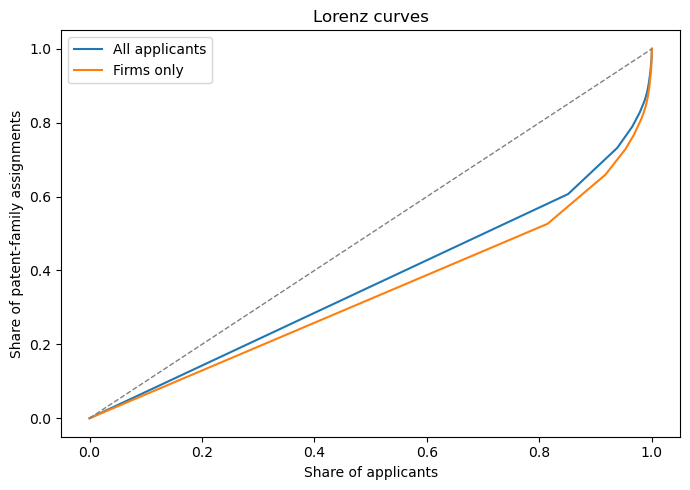

In [ ]:
all_counts = complete.groupby('applicant')['unit_id'].nunique()
firm_counts = firms_only.groupby('applicant')['unit_id'].nunique()
results = pd.DataFrame({
    'All applicants': six_measures(all_counts.to_numpy()),
    'Firms only': six_measures(firm_counts.to_numpy())
})
display(results.round(4))
results.to_csv(OUTPUT_DIR / 'concentration.csv')

fig, ax = plt.subplots(figsize=(7, 5))
for label, counts in [('All applicants', all_counts), ('Firms only', firm_counts)]:
    x, y = lorenz_curve(counts.to_numpy())
    ax.plot(x, y, label=label)
ax.plot([0, 1], [0, 1], '--', color='grey', linewidth=1)
ax.set(xlabel='Share of applicants', ylabel='Share of patent-family assignments',
       title='Lorenz curves')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
sensitivity_rows = []
for method in ('dictionary', 'cleanco', 'terrorizer'):
    candidate = prepare_applicants(
        raw_sector, method=method,
        terrorizer_map=terrorizer_name_map if method == 'terrorizer' else None
    )
    candidate = candidate[candidate['year'] <= LAST_COMPLETE_YEAR]
    for population, subset in [('All applicants', candidate),
                               ('Firms only', candidate[candidate['type'] == 'firm'])]:
        counts = subset.groupby('applicant')['unit_id'].nunique().to_numpy()
        if len(counts):
            sensitivity_rows.append({
                'name_method': method,
                'role': 'MAIN' if method == 'terrorizer' else 'BASELINE',
                'population': population,
                'applicants': len(counts),
                'CR4 (%)': concentration_ratio(counts, 4),
                'HH': herfindahl(counts),
                'Gini': gini(counts)
            })
name_sensitivity = pd.DataFrame(sensitivity_rows)
display(name_sensitivity.round(4))
name_sensitivity.to_csv(OUTPUT_DIR / 'name_method_sensitivity.csv', index=False)
assert set(name_sensitivity['name_method']) == {'dictionary', 'cleanco', 'terrorizer'}
print('MAIN indicators above and below use: Terrorizer (blocked source-based)')

,name_method,role,population,applicants,CR4 (%),HH,Gini
0,dictionary,BASELINE,All applicants,2042,5.1435,0.0017,0.2653
1,dictionary,BASELINE,Firms only,905,10.2070,0.0051,0.3237
2,cleanco,BASELINE,All applicants,2034,5.1597,0.0017,0.2658
3,cleanco,BASELINE,Firms only,897,10.2952,0.0052,0.3241
4,terrorizer,MAIN,All applicants,2028,5.1688,0.0017,0.2665
5,terrorizer,MAIN,Firms only,895,10.3249,0.0052,0.3241


MAIN indicators above and below use: Terrorizer (blocked source-based)


,window_end,population,applicants,CR4 (%),HH,1/HH
30,2017,All applicants,386,12.0219,0.0071,140.5133
31,2017,Firms only,254,17.1053,0.0125,79.8673
32,2018,All applicants,476,13.1579,0.0087,115.1787
33,2018,Firms only,303,19.7339,0.0175,57.0550
34,2019,All applicants,494,10.4435,0.0065,154.3763
35,2019,Firms only,290,15.7895,0.0141,70.7385
36,2020,All applicants,503,8.8023,0.0048,210.3587
37,2020,Firms only,275,12.0548,0.0097,103.1952
38,2021,All applicants,437,7.0826,0.0040,250.6408
39,2021,Firms only,201,9.3985,0.0078,128.1812


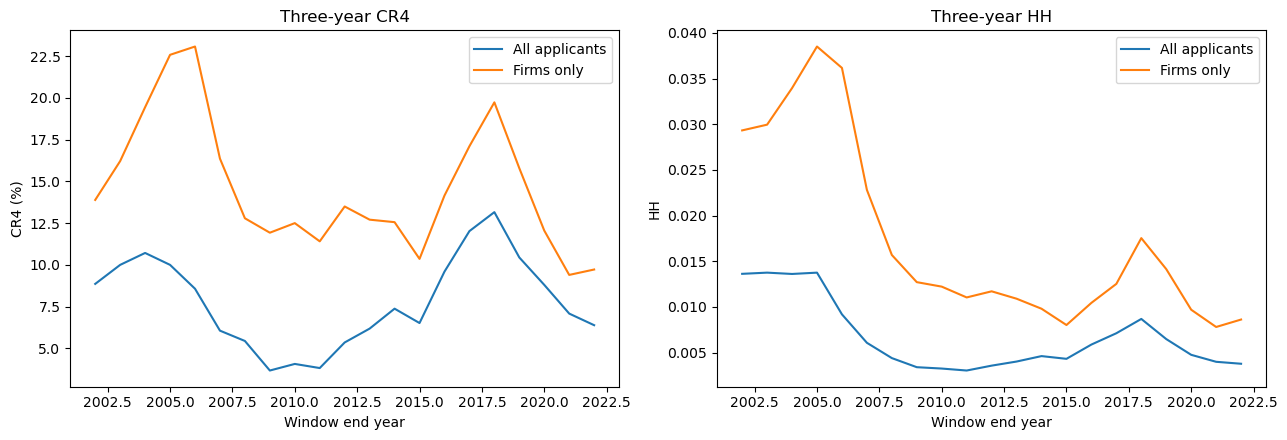

In [ ]:
trend_rows = []
for end_year in range(YEAR_MIN + WINDOW - 1, LAST_COMPLETE_YEAR + 1):
    for label, frame in [('All applicants', complete), ('Firms only', firms_only)]:
        window = frame[frame['year'].between(end_year - WINDOW + 1, end_year)]
        counts = window.groupby('applicant')['unit_id'].nunique().to_numpy()
        if len(counts) == 0:
            continue
        trend_rows.append({
            'window_end': end_year, 'population': label,
            'applicants': len(counts), 'CR4 (%)': concentration_ratio(counts, 4),
            'HH': herfindahl(counts), '1/HH': 1/herfindahl(counts)
        })
concentration_trend = pd.DataFrame(trend_rows)
display(concentration_trend.tail(12).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for label, group in concentration_trend.groupby('population'):
    axes[0].plot(group['window_end'], group['CR4 (%)'], label=label)
    axes[1].plot(group['window_end'], group['HH'], label=label)
axes[0].set(title='Three-year CR4', xlabel='Window end year', ylabel='CR4 (%)')
axes[1].set(title='Three-year HH', xlabel='Window end year', ylabel='HH')
for axis in axes:
    axis.legend()
plt.tight_layout()
plt.show()
concentration_trend.to_csv(OUTPUT_DIR / 'concentration_trend.csv', index=False)

In [ ]:
by_applicant = complete.groupby('applicant')
top_applicants = pd.DataFrame({
    'type': by_applicant['type'].first(),
    'country': by_applicant['ctry'].first(),
    'families': by_applicant['unit_id'].nunique(),
    f'families since {SPLIT_YEAR}': complete[
        complete['year'] >= SPLIT_YEAR].groupby('applicant')['unit_id'].nunique(),
    'first year in the sector': by_applicant['year'].min(),
    'last year in the sector': by_applicant['year'].max()
}).fillna({f'families since {SPLIT_YEAR}': 0})
top_applicants['status'] = np.where(
    top_applicants['first year in the sector'] < SPLIT_YEAR,
    'incumbent', 'entrant'
)
top_applicants = top_applicants.sort_values('families', ascending=False)
display(top_applicants.head(TOP_N))
top_applicants.to_csv(OUTPUT_DIR / 'top_applicants.csv')

,type,country,families,families since 2015,first year in the sector,last year in the sector,status
applicant,,,,,,,
SAMSUNG HEAVY INDUSTRIES,firm,KR,71,60.0,2008,2021,incumbent
GE GENERAL ELECTRIC,firm,US,26,15.0,2006,2019,incumbent
ITREC,mixed,NL,26,19.0,2002,2022,incumbent
BOEING,firm,US,24,9.0,2006,2020,incumbent
WALMART APOLLO,firm,US,22,22.0,2015,2017,entrant
ZHEJIANG OCEAN UNIVERSITY,university,CN,18,17.0,2014,2021,incumbent
HARBIN ENGINEERING UNIVERSITY,university,None,17,17.0,2016,2022,entrant
BRAIN,firm,US,16,7.0,2013,2017,incumbent
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,CN,15,15.0,2015,2022,entrant


In [ ]:
top_review_file = OUTPUT_DIR / f'top_applicants_review_{ENV.lower()}.csv'
top_review_sample = (top_applicants.head(TOP_N).reset_index()
                     .rename(columns={'index': 'applicant'}).copy())
if 'applicant' not in top_review_sample.columns:
    top_review_sample = top_review_sample.rename(columns={top_review_sample.columns[0]: 'applicant'})
top_review_sample['review_status'] = 'PENDING'
top_review_sample['review_note'] = ''
if not top_review_file.exists():
    top_review_sample.to_csv(top_review_file, index=False)
    print('Created:', top_review_file)
else:
    print('Preserved existing manual applicant review:', top_review_file)
top_review_complete = False
if top_review_file.exists():
    previous = pd.read_csv(top_review_file)
    if set(previous['applicant'].astype(str)) == set(top_review_sample['applicant'].astype(str)):
        top_review_complete = bool(len(previous)) and previous['review_status'].fillna('').str.upper().isin(
            ['CONFIRMED']).all()
    else:
        print('WARNING: The saved top-applicant review does not match the current top list.')
display(top_review_sample[['applicant', 'type', 'families', 'status', 'review_status']])

Preserved existing manual applicant review: outputs/step2/test/quality_gated/top_applicants_review_test.csv


,applicant,type,families,status,review_status
0,SAMSUNG HEAVY INDUSTRIES,firm,71,incumbent,PENDING
1,GE GENERAL ELECTRIC,firm,26,incumbent,PENDING
2,ITREC,mixed,26,incumbent,PENDING
3,BOEING,firm,24,incumbent,PENDING
4,WALMART APOLLO,firm,22,entrant,PENDING
5,ZHEJIANG OCEAN UNIVERSITY,university,18,incumbent,PENDING
6,HARBIN ENGINEERING UNIVERSITY,university,17,entrant,PENDING
7,BRAIN,firm,16,incumbent,PENDING
8,JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,15,entrant,PENDING
9,VESTAS,firm,15,incumbent,PENDING


In [ ]:
psn_ids = [int(i) for i in pd.to_numeric(raw_sector['psn_id'], errors='coerce').dropna().unique()]
first_parts = []
for ids in batches(psn_ids):
    q_first = (
        db.query(TLS206_PERSON.psn_id,
                 func.min(TLS201_APPLN.earliest_filing_year).label('first_patent_year'))
        .join(TLS207_PERS_APPLN,
              TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
        .join(TLS201_APPLN,
              TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
        .filter(TLS206_PERSON.psn_id.in_(ids),
                TLS201_APPLN.ipr_type == IPR_TYPE,
                TLS207_PERS_APPLN.applt_seq_nr > 0,
                TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX))
        .group_by(TLS206_PERSON.psn_id)
    )
    part = patstat.df(q_first)
    if not part.empty:
        first_parts.append(part)

first_patents = (pd.concat(first_parts, ignore_index=True)
                 if first_parts else pd.DataFrame(columns=['psn_id', 'first_patent_year']))
if first_patents.empty:
    first_ever = pd.Series(dtype=float)
else:
    psn = (raw_sector[['psn_id', 'psn_name']]
           .drop_duplicates()
           .merge(first_patents, on='psn_id'))

    psn['psn_name'] = psn['psn_name'].fillna('').astype(str).str.strip()
    psn['applicant'] = psn['psn_name'].map(terrorizer_name_map)
    if psn['applicant'].isna().any():
        missing = psn.loc[psn['applicant'].isna(), 'psn_name'].drop_duplicates().head(5).tolist()
        raise ValueError(f'Names missing from the sector Terrorizer map: {missing}')
    first_ever = psn.groupby('applicant')['first_patent_year'].min()
print('Applicants with all-field patent history:', len(first_ever))

Applicants with all-field patent history: 2040


,active_applicants,new_to_the_sector,last_observed,rate of disappearance (%),entrants' share of families (%),new_to_patenting
year,,,,,,
2000,28,28,21,75.00,100.00,16
2001,28,26,22,78.57,94.44,18
2002,22,22,12,54.55,100.00,12
2003,27,26,23,85.19,94.74,19
2004,31,30,25,80.65,93.33,21
2005,19,15,16,84.21,100.00,13
2006,77,72,64,83.12,96.43,64
2007,90,86,77,85.56,96.97,66
2008,110,98,91,82.73,97.92,74


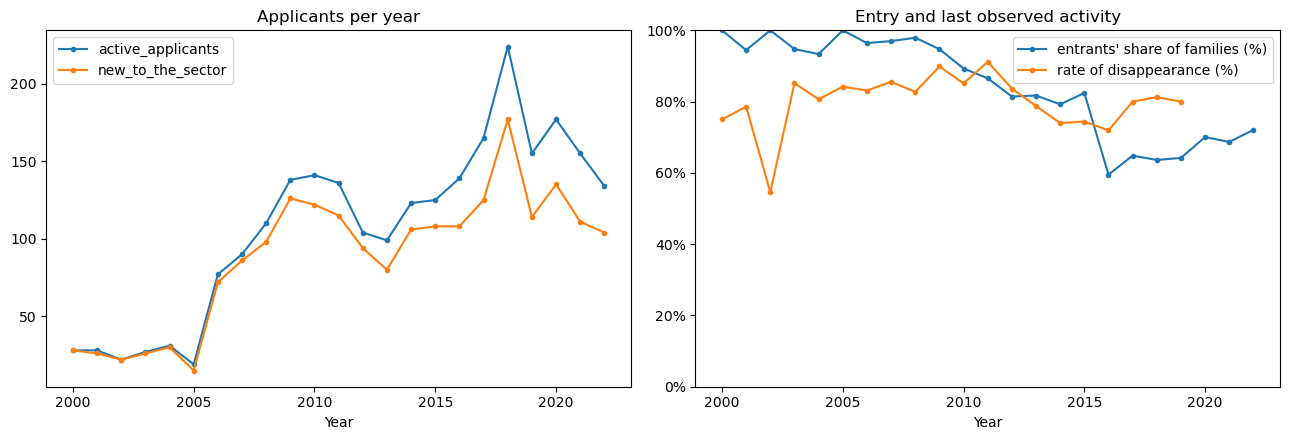

In [ ]:
first_year = by_applicant['year'].min()
last_year = by_applicant['year'].max()
active = complete[['applicant', 'year']].drop_duplicates().copy()
active['new to the sector'] = active['year'].eq(active['applicant'].map(first_year))
active['last family'] = active['year'].eq(active['applicant'].map(last_year))
entry_exit = active.groupby('year').agg(
    active_applicants=('applicant', 'count'),
    new_to_the_sector=('new to the sector', 'sum'),
    last_observed=('last family', 'sum')
)
entry_exit['rate of disappearance (%)'] = (
    100*entry_exit['last_observed']/entry_exit['active_applicants'])
entry_exit.loc[entry_exit.index > LAST_COMPLETE_YEAR - 3,
               'rate of disappearance (%)'] = np.nan
new_links = complete.assign(new=complete['year'].eq(complete['applicant'].map(first_year)))
entry_exit["entrants' share of families (%)"] = (
    100*new_links.groupby(['year','unit_id'])['new'].any().groupby('year').mean()
)
if not first_ever.empty:
    active['new to patenting'] = active['year'].eq(active['applicant'].map(first_ever))
    entry_exit['new_to_patenting'] = active.groupby('year')['new to patenting'].sum()
display(entry_exit.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
entry_exit[['active_applicants', 'new_to_the_sector']].plot(ax=axes[0], marker='o', ms=3)
entry_exit[["entrants' share of families (%)", 'rate of disappearance (%)']].plot(
    ax=axes[1], marker='o', ms=3)
axes[0].set(title='Applicants per year', xlabel='Year')
axes[1].set(title='Entry and last observed activity', xlabel='Year', ylim=(0,100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
plt.tight_layout()
plt.show()
entry_exit.to_csv(OUTPUT_DIR / 'entry_exit.csv')

In [ ]:
print('Families with CPC codes:', family_cpc['unit_id'].nunique())
print('Distinct CPC codes:', family_cpc['cpc'].nunique())
display(family_cpc.head(10))

Families with CPC codes: 1874
Distinct CPC codes: 4826


,unit_id,year,cpc
0,40456687,2008,B63B27/04
1,40456687,2008,B63B35/003
2,40456687,2008,E02B17/06
3,40456687,2008,E02B17/0818
4,40456687,2008,E02B2017/0091
5,40456687,2008,F03D13/10
6,40456687,2008,F03D13/40
7,40456687,2008,F05B2240/95
8,55024707,2014,B63B25/00
9,55024707,2014,B63B25/002


,families 2013-2017,families 2018-2022,growth (%)
subfield,,,
B63B35/00,160,390,143.8
G05D1/00,221,92,-58.4
B63B2035/00,25,86,244.0
B63G8/00,41,32,-22.0
G05D1/02,18,27,50.0
G08G3/00,3,4,33.3
B63G13/00,2,2,0.0
B64U70/93,8,1,-87.5
B64U60/10,4,0,-100.0


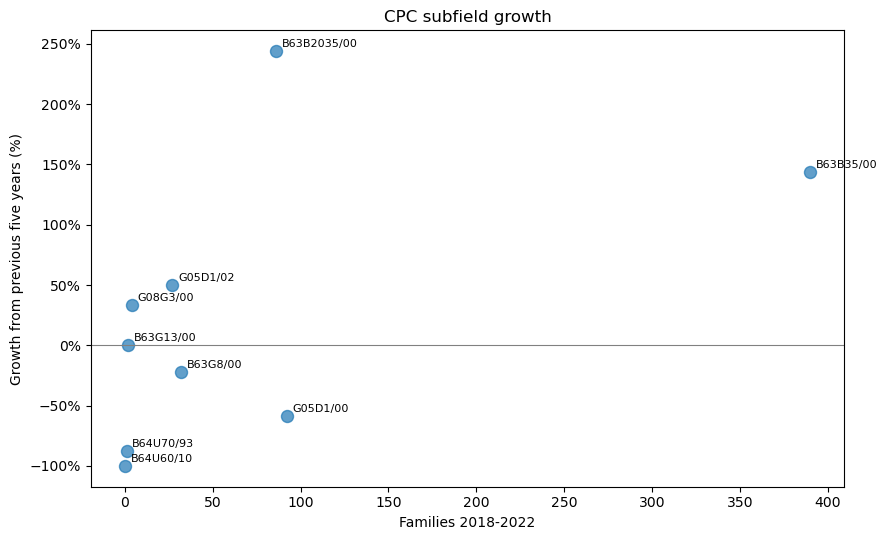

In [ ]:
PAST = (LAST_COMPLETE_YEAR - 9, LAST_COMPLETE_YEAR - 5)
RECENT = (LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)

def subfield(cpc):

    code = str(cpc).replace(' ', '')
    if '/' not in code:
        return None
    main, subgroup = code.split('/', 1)
    return f'{main}/{subgroup[:2]}' if subgroup else None

if not family_cpc.empty:
    in_sector = family_cpc[family_cpc['cpc'].str.startswith(SECTOR_CPC_PREFIXES)].copy()
    in_sector['subfield'] = in_sector['cpc'].map(subfield)
    in_sector = in_sector.dropna(subset=['subfield']).drop_duplicates(['unit_id', 'subfield'])
    previous = in_sector[in_sector['year'].between(*PAST)].groupby('subfield')['unit_id'].nunique()
    current = in_sector[in_sector['year'].between(*RECENT)].groupby('subfield')['unit_id'].nunique()
    old_col = f'families {PAST[0]}-{PAST[1]}'
    new_col = f'families {RECENT[0]}-{RECENT[1]}'
    subfields = pd.DataFrame({old_col: previous, new_col: current}).fillna(0).astype(int)
    subfields['growth (%)'] = np.where(
        subfields[old_col].gt(0),
        (subfields[new_col] / subfields[old_col] - 1) * 100, np.nan)
    subfields = subfields.sort_values(new_col, ascending=False)
    display(subfields.head(20).round(1))
    subfields.to_csv(OUTPUT_DIR / 'cpc_growth.csv')
    plot = subfields[subfields[old_col].gt(0)]
    if not plot.empty:
        fig, ax = plt.subplots(figsize=(9, 5.5))
        ax.scatter(plot[new_col], plot['growth (%)'], s=75, alpha=0.7)
        for label, row in plot.iterrows():
            ax.annotate(label, (row[new_col], row['growth (%)']), fontsize=8,
                        xytext=(4,3), textcoords='offset points')
        ax.axhline(0, color='grey', lw=0.8)
        ax.set(xlabel=f'Families {RECENT[0]}-{RECENT[1]}',
               ylabel='Growth from previous five years (%)',
               title='CPC subfield growth')
        ax.yaxis.set_major_formatter(PercentFormatter(100))
        plt.tight_layout()
        plt.show()
else:
    subfields = pd.DataFrame()

In [ ]:
pest = pd.DataFrame([
    {
        'dimension': 'Political',
        'factor': 'Autonomous vessel safety framework',
        'evidence': 'IMO adopted the non-mandatory MASS Code in May 2026, effective 1 July 2026. '
                    'It primarily covers SOLAS cargo ships, with recommended application to smaller MASS where practicable.',
        'source_url': 'https://www.imo.org/en/mediacentre/pressbriefings/pages/imo-adopts-mass-code.aspx',
        'opportunity_or_threat': 'Both',
        'strategic_implication': 'Safety evidence and national approval routes can influence development and deployment.',
        'priority': 'High (proposed)',
        'priority_reason': 'Approvals and operational safety are potential project gates.',
        'recommended_action': 'Map applicable national rules and safety approvals for each target USV application.'
    },
    {
        'dimension': 'Economic',
        'factor': 'Demand for efficient marine data collection',
        'evidence': 'NOAA describes operational uses of USVs for oceanographic data, seabed mapping and remote observations. '
                    'Its materials do not establish a universal cost-saving percentage.',
        'source_url': 'https://oceanexplorer.noaa.gov/technology/usv/',
        'opportunity_or_threat': 'Opportunity',
        'strategic_implication': 'Mapping and monitoring may offer use cases worth evaluating commercially.',
        'priority': 'Medium (proposed)',
        'priority_reason': 'Commercial value is plausible but needs application-specific cost evidence.',
        'recommended_action': 'Compare mission economics with crewed alternatives for 2–3 defined use cases.'
    },
    {
        'dimension': 'Social',
        'factor': 'Remote operator skills and safety oversight',
        'evidence': 'EMSA CMOROC identifies changed tasks, competencies and training needs for MASS remote operators.',
        'source_url': 'https://www.emsa.europa.eu/we-do/safety/human-element/items.html?cid=486&id=5089',
        'opportunity_or_threat': 'Both',
        'strategic_implication': 'Human oversight remains important even as shipboard tasks are automated.',
        'priority': 'High (proposed)',
        'priority_reason': 'Competence and oversight affect operational acceptance and safety.',
        'recommended_action': 'Design operator training, escalation procedures and human-in-the-loop demonstrations.'
    },
    {
        'dimension': 'Technological',
        'factor': 'Autonomy, communications and risk assessment',
        'evidence': 'EMSA describes digitalisation and machine learning as enablers of MASS and highlights the '
                    'need for risk assessment of novel autonomous-vessel concepts.',
        'source_url': 'https://www.emsa.europa.eu/mass.html',
        'opportunity_or_threat': 'Both',
        'strategic_implication': 'Navigation robustness, connectivity and system assurance can differentiate solutions.',
        'priority': 'High (proposed)',
        'priority_reason': 'Technical reliability is central to deployment and integration.',
        'recommended_action': 'Evaluate fail-safe navigation, degraded-link operation and verification evidence.'
    }
])

display(pest)
pest.to_csv(OUTPUT_DIR / 'pest_evidence.csv', index=False)

,dimension,factor,evidence,source_url,opportunity_or_threat,strategic_implication,priority,priority_reason,recommended_action
0,Political,Autonomous vessel safety framework,IMO adopted the non-mandatory MASS Code in May...,https://www.imo.org/en/mediacentre/pressbriefi...,Both,Safety evidence and national approval routes c...,High (proposed),Approvals and operational safety are potential...,Map applicable national rules and safety appro...
1,Economic,Demand for efficient marine data collection,NOAA describes operational uses of USVs for oc...,https://oceanexplorer.noaa.gov/technology/usv/,Opportunity,Mapping and monitoring may offer use cases wor...,Medium (proposed),Commercial value is plausible but needs applic...,Compare mission economics with crewed alternat...
2,Social,Remote operator skills and safety oversight,"EMSA CMOROC identifies changed tasks, competen...",https://www.emsa.europa.eu/we-do/safety/human-...,Both,Human oversight remains important even as ship...,High (proposed),Competence and oversight affect operational ac...,"Design operator training, escalation procedure..."
3,Technological,"Autonomy, communications and risk assessment",EMSA describes digitalisation and machine lear...,https://www.emsa.europa.eu/mass.html,Both,"Navigation robustness, connectivity and system...",High (proposed),Technical reliability is central to deployment...,"Evaluate fail-safe navigation, degraded-link o..."


In [ ]:
wind_families = (family_cpc.loc[
    family_cpc['cpc'].str.startswith(('F03D', 'Y02E10/72'), na=False), 'unit_id'].nunique()
    if not family_cpc.empty else np.nan)

scope_review_status = ('COMPLETE' if scope_review_complete else
                       'PENDING' if RUN_SCOPE_REVIEW else 'NOT RUN')
top_review_complete = globals().get('top_review_complete', False)
applicant_review_status = 'COMPLETE' if top_review_complete else 'PENDING'
final_ready = bool(
    ENV == 'PROD' and step1_definition_match is True
    and scope_review_complete and top_review_complete
    and terrorizer_review_complete
    and PEST_GROUP_AGREED and FINAL_SIGNOFF
)
audit = pd.DataFrame([{
    'source': 'TIP / PATSTAT',
    'environment': ENV,
    'families_with_applicants': int(links['unit_id'].nunique()),
    'families_through_cutoff': int(complete['unit_id'].nunique()),
    'name_method_for_indicators': 'terrorizer (blocked, conservative quality gate; unverified)',
    'terrorizer_gold_evaluation_enabled': RUN_TERRORIZER_GOLD,
    'terrorizer_all_sector_names_assigned': terrorizer_full_name_coverage,
    'terrorizer_sector_names': len(sector_terrorizer_assignments),
    'terrorizer_total_groups': len(sector_terrorizer_groups),
    'terrorizer_raw_multi_name_groups': int(raw_terrorizer_groups['n_names'].gt(1).sum()),
    'terrorizer_auto_split_raw_groups': int(auto_qc['automatic_decision'].eq('AUTO_SPLIT').sum()),
    'terrorizer_automatic_screen_validated': False,
    'terrorizer_multi_name_groups_applied': terrorizer_groups_applied,
    'terrorizer_group_review_complete': terrorizer_review_complete,
    'terrorizer_is_main_indicator_method': True,
    'step1_definition_match': step1_definition_match,
    'step1_check_message': step1_check_message,
    'scope_review_status': scope_review_status,
    'top_applicants_review_status': applicant_review_status,
    'first_patent_any_field_available': not first_ever.empty,
    'cpc_available': not family_cpc.empty,
    'wind_tagged_families_flag_only': wind_families,
    'pest_priorities_agreed_with_group': PEST_GROUP_AGREED,
    'ready_for_final_sector_conclusions': final_ready
}])
display(audit.T.rename(columns={0: 'value'}))
audit.to_csv(OUTPUT_DIR / 'step2_audit.csv', index=False)
if not final_ready:
    print('TEST COMPUTATION COMPLETE WHEN CELLS RUN; academic validation and PROD remain open.')

,value
source,TIP / PATSTAT
environment,TEST
families_with_applicants,1918
families_through_cutoff,1902
name_method_for_indicators,"terrorizer (blocked, conservative quality gate..."
terrorizer_gold_evaluation_enabled,True
terrorizer_all_sector_names_assigned,True
terrorizer_sector_names,2114
terrorizer_total_groups,2040
terrorizer_raw_multi_name_groups,278


TEST COMPUTATION COMPLETE WHEN CELLS RUN; academic validation and PROD remain open.
